<div align="center">
<h1>Uji Zero-Shot Domain Shift ke RDD-indo-v4</h1>
<p>Skenario 3 (data baru): bobot N-RDD2024 (sumber, Asia) diuji langsung pada RDD-indo-v4 (target, 308 citra valid) tanpa fine-tuning. Adaptasi dari notebook 05_zero_shot_indo_v2.ipynb; perbedaan utama: v4 hanya punya split valid dan 5 kelas (tanpa manhole), sehingga mapping target-ke-sumber disesuaikan.</p>
</div>

In [1]:
from pathlib import Path
from collections import Counter

REPO = next((q for q in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (q / 'data' / 'RDD-indo-v4').exists()), Path.cwd().resolve())
print('REPO:', REPO)
SRC_NAMES = ['Longitudinal_Crack', 'Transverse_Crack', 'Alligator_Crack', 'Pothole', 'manhole', 'patchy_road']
TGT_NAMES = ['alligator crack', 'longitudinal crack', 'patchy road', 'pothole', 'tranverse crack']
INDO = REPO / 'data/RDD-indo-v4'

for split in ['valid']:
    imgs = list((INDO / split / 'images').glob('*'))
    lbls = list((INDO / split / 'labels').glob('*.txt'))
    c, empty = Counter(), 0
    for f in lbls:
        ls = [l.strip() for l in f.read_text().splitlines() if l.strip()]
        if not ls:
            empty += 1
        for l in ls:
            c[int(l.split()[0])] += 1
    print(f'{split}: {len(imgs)} images, {len(lbls)} label files, {empty} empty')
    print('  instances per target-id:', dict(sorted(c.items())), f"-> total {sum(c.values())}")
    print('  artinya:', {TGT_NAMES[k]: v for k, v in sorted(c.items())})

REPO: /mnt/Data/01_Akademik/TA-Project
valid: 307 images, 307 label files, 39 empty
  instances per target-id: {0: 48, 1: 235, 2: 22, 3: 75, 4: 134} -> total 514
  artinya: {'alligator crack': 48, 'longitudinal crack': 235, 'patchy road': 22, 'pothole': 75, 'tranverse crack': 134}


## ***Pemetaan Kelas***
---
Urutan kelas sumber dan target berbeda, dan v4 tidak punya kelas manhole (5 kelas vs 6 kelas sumber). Label v4 dipetakan ke urutan sumber sebelum evaluasi; isi valid/v4 dipakai sebagai split test remap.

In [2]:
import shutil

TGT2SRC = {0: 2, 1: 0, 2: 5, 3: 3, 4: 1}  # target-id (v4, 5 kelas) -> source-id (cocok via nama kelas)
print('mapping target->source:', TGT2SRC)
assert [SRC_NAMES[TGT2SRC[i]] for i in range(5)] == ['Alligator_Crack', 'Longitudinal_Crack', 'patchy_road', 'Pothole', 'Transverse_Crack']

EV = REPO / 'runs/rdd_yolov8n_local/evaluation/zero_shot_indo_v4'
EV.mkdir(parents=True, exist_ok=True)
REM = REPO / 'runs/rdd_yolov8n_local/indo_v4_remapped'
if REM.exists():
    shutil.rmtree(REM)
(REM / 'test' / 'images').mkdir(parents=True)
(REM / 'test' / 'labels').mkdir(parents=True)
for img in (INDO / 'valid' / 'images').iterdir():
    (REM / 'test' / 'images' / img.name).symlink_to(img.resolve())
for lf in (INDO / 'valid' / 'labels').glob('*.txt'):
    out = []
    for l in lf.read_text().splitlines():
        if not l.strip():
            continue
        p = l.split()
        out.append(f"{TGT2SRC[int(p[0])]} " + ' '.join(p[1:]))
    (REM / 'test' / 'labels' / lf.name).write_text('\n'.join(out) + ('\n' if out else ''))

(REM / 'indo_v4_remapped.yaml').write_text(
    f"path: {REM}\ntrain: test/images\ntest: test/images\nval: test/images\nnc: 6\nnames: {SRC_NAMES}\n")
print('remapped yaml:', REM / 'indo_v4_remapped.yaml')
print('sumber: valid/images =', len(list((INDO / 'valid/images').iterdir())), '| remap test/images =', len(list((REM / 'test/images').iterdir())))
print('remap test/labels =', len(list((REM / 'test/labels').glob('*.txt'))))

mapping target->source: {0: 2, 1: 0, 2: 5, 3: 3, 4: 1}


remapped yaml: /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v4_remapped/indo_v4_remapped.yaml
sumber: valid/images = 307 | remap test/images = 307
remap test/labels = 307


## ***Prediksi Zero-Shot***
---
Val tiap bobot pada RDD-indo-v4 (isi valid/v4 sebagai split test remap; conf=0.001, iou=0.6, sama seperti Skenario 1 dan notebook 05/v2).

In [3]:
import sys, json
import torch
import numpy as np
import pandas as pd
sys.path.insert(0, str(REPO / 'code/models'))
from ultralytics import YOLO
_PATCHED = False
def ensure_patch():
    global _PATCHED
    if not _PATCHED:
        from custom_modules import patch_ultralytics
        patch_ultralytics()
        _PATCHED = True
        print('patch custom aktif (wajib untuk PD/RD)')

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)
DATA = str(REM / 'indo_v4_remapped.yaml')
WEIGHTS = {
    'yolov8n': REPO / 'runs/rdd_yolov8n_local/experiments/yolov8n_class_weight/weights/best.pt',
    'yolov12n': REPO / 'runs/rdd_yolov8n_local/experiments/yolov12n_class_weight/weights/best.pt',
    'yolov26n': REPO / 'runs/rdd_yolov8n_local/experiments/yolov26n_class_weight/weights/best.pt',
    'yolov8_pd': REPO / 'runs/rdd_yolov8n_local/experiments/yolov8_pd_class_weight/weights/best.pt',
    'yolo_rd': REPO / 'runs/rdd_yolov8n_local/experiments/yolo_rd_class_weight/weights/best.pt',
}
for k, v in WEIGHTS.items():
    print(k, 'OK' if v.exists() else f'HILANG: {v}')
SRC_TEST = {'yolov8n': 0.648, 'yolov12n': 0.654, 'yolov26n': 0.625, 'yolov8_pd': 0.646, 'yolo_rd': 0.661}
ZS = {}      # ringkasan skalar per model
ZS_PC = {}   # metrik per-kelas per model


def per_class_metrics(metrics, class_names):
    """P/R/F1/mAP per kelas (class-id asli).

    Catatan penting: `Metric.class_result(pos)` bersifat POSISIONAL terhadap
    `metrics.box.ap_class_index`, bukan class-id. Kelas yang tidak punya GT di
    split target (di sini: manhole) tidak masuk `ap_class_index`, sehingga
    pemetaan position -> class-id wajib memakai ap_class_index. Kelas tanpa GT
    dilaporkan NaN (tidak dievaluasi), bukan 0.
    """
    box = metrics.box
    ap_idx = [int(c) for c in np.atleast_1d(box.ap_class_index)]
    rows = []
    for class_id, class_name in enumerate(class_names):
        if class_id in ap_idx:
            pos = ap_idx.index(class_id)
            precision, recall, ap50, ap5095 = (float(v) for v in box.class_result(pos))
            f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
        else:
            precision = recall = ap50 = ap5095 = f1 = float('nan')
        rows.append({'class_id': class_id, 'class_name': class_name,
                     'precision': precision, 'recall': recall,
                     'f1': f1, 'mAP50': ap50, 'mAP50-95': ap5095,
                     'evaluated': class_id in ap_idx})
    return pd.DataFrame(rows)


def class_support(data_yaml, split='test'):
    """Jumlah GT instance per kelas dari split terpilih."""
    root = Path(data_yaml).parent
    counts = {}
    for lf in (root / split / 'labels').glob('*.txt'):
        for line in lf.read_text().splitlines():
            if line.strip():
                cid = int(line.split()[0])
                counts[cid] = counts.get(cid, 0) + 1
    return counts


SUPPORT = class_support(DATA)
print('support per kelas (target):', {SRC_NAMES[k]: v for k, v in sorted(SUPPORT.items())})
print('kelas tanpa GT (tidak dievaluasi Ultralytics):',
      [SRC_NAMES[k] for k in range(len(SRC_NAMES)) if SUPPORT.get(k, 0) == 0])


def safe_weighted_mean(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    valid = np.isfinite(values) & np.isfinite(weights)
    if not valid.any() or weights[valid].sum() == 0:
        return float('nan')
    return float(np.average(values[valid], weights=weights[valid]))


def run_zs(name):
    if name in ('yolov8_pd', 'yolo_rd'):
        ensure_patch()
    m = YOLO(str(WEIGHTS[name]))
    r = m.val(data=DATA, split='test', imgsz=640, conf=0.001, iou=0.6, verbose=False, device=DEVICE)
    pc = per_class_metrics(r, SRC_NAMES)
    pc['support'] = pc['class_id'].map(SUPPORT).fillna(0).astype(int)
    # macro dihitung atas kelas yang benar-benar dievaluasi (punya GT)
    ev = pc[pc['evaluated']]
    macro_f1 = float(ev['f1'].mean())
    weighted_f1 = safe_weighted_mean(ev['f1'], ev['support'])
    d = {'P': float(r.box.p.mean()), 'R': float(r.box.r.mean()),
         'mAP50': float(r.box.map50), 'mAP5095': float(r.box.map),
         'macro_f1': macro_f1, 'weighted_f1': weighted_f1,
         'n_eval_classes': int(len(ev))}
    ZS[name] = d
    ZS_PC[name] = pc
    print(f"{name}: P={d['P']:.3f} R={d['R']:.3f} mAP50={d['mAP50']:.3f} "
          f"mAP50-95={d['mAP5095']:.3f} F1macro={macro_f1:.3f} "
          f"F1weighted={weighted_f1:.3f} (n_kelas={len(ev)})")
    torch.cuda.empty_cache()
    return d


device: 0
yolov8n OK
yolov12n OK
yolov26n OK
yolov8_pd OK
yolo_rd OK
support per kelas (target): {'Longitudinal_Crack': 235, 'Transverse_Crack': 134, 'Alligator_Crack': 48, 'Pothole': 75, 'patchy_road': 22}
kelas tanpa GT (tidak dievaluasi Ultralytics): ['manhole']


In [4]:
run_zs('yolov8n')

Ultralytics 8.4.115 🚀 Python-3.12.15 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)


Model summary (fused): 73 layers, 3,006,818 parameters, 0 gradients, 8.1 GFLOPs


val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 558.4±96.0 MB/s, size: 73.7 KB)


val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v4_remapped/test/labels... 256 images, 33 backgrounds, 0 corrupt: 83% ━━━━━━━━━━── 256/307 765.1it/s 0.1s<0.1s

val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v4_remapped/test/labels... 307 images, 39 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 307/307 2.6Kit/s 0.1s

...

                   all        307        514      0.304      0.311       0.25      0.103


Speed: 0.9ms preprocess, 5.0ms inference, 0.0ms loss, 0.5ms postprocess per image


Results saved to /mnt/Data/01_Akademik/TA-Project/runs/detect/val-84


yolov8n: P=0.304 R=0.311 mAP50=0.250 mAP50-95=0.103 F1macro=0.306 F1weighted=0.392 (n_kelas=5)


{'P': 0.303506113743369,
 'R': 0.31055805160901795,
 'mAP50': 0.24966872698398895,
 'mAP5095': 0.10315435761954574,
 'macro_f1': 0.30604396129647843,
 'weighted_f1': 0.3916465452091958,
 'n_eval_classes': 5}

In [5]:
run_zs('yolov12n')

Ultralytics 8.4.115 🚀 Python-3.12.15 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)


YOLOv12n summary (fused): 159 layers, 2,557,898 parameters, 0 gradients, 7.3 GFLOPs


val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 490.1±78.5 MB/s, size: 60.7 KB)


val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v4_remapped/test/labels.cache... 307 images, 39 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 307/307 107.3Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/20 1.1it/s 0.3s<17.2s

...

                   all        307        514      0.424      0.352      0.332      0.141


Speed: 0.8ms preprocess, 7.2ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to /mnt/Data/01_Akademik/TA-Project/runs/detect/val-85


yolov12n: P=0.424 R=0.352 mAP50=0.332 mAP50-95=0.141 F1macro=0.378 F1weighted=0.464 (n_kelas=5)


{'P': 0.42449715001238386,
 'R': 0.3522853431103669,
 'mAP50': 0.33232663982443456,
 'mAP5095': 0.1407697928032673,
 'macro_f1': 0.37823811582406286,
 'weighted_f1': 0.46429933713551336,
 'n_eval_classes': 5}

In [6]:
run_zs('yolov26n')

Ultralytics 8.4.115 🚀 Python-3.12.15 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)


YOLO26n summary (fused): 122 layers, 2,376,006 parameters, 0 gradients, 5.3 GFLOPs


val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 526.7±146.7 MB/s, size: 56.2 KB)


val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v4_remapped/test/labels.cache... 307 images, 39 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 307/307 161.0Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/20 1.6it/s 0.2s<12.2s

...

                   all        307        514       0.28      0.295      0.239     0.0992


Speed: 1.0ms preprocess, 4.8ms inference, 0.0ms loss, 0.2ms postprocess per image


Results saved to /mnt/Data/01_Akademik/TA-Project/runs/detect/val-86


yolov26n: P=0.280 R=0.295 mAP50=0.239 mAP50-95=0.099 F1macro=0.274 F1weighted=0.359 (n_kelas=5)


{'P': 0.2803495088811222,
 'R': 0.2946443652145462,
 'mAP50': 0.2394871550283973,
 'mAP5095': 0.09920660621983476,
 'macro_f1': 0.273874947997265,
 'weighted_f1': 0.35883676902010664,
 'n_eval_classes': 5}

In [7]:
run_zs('yolov8_pd')

patch custom aktif (wajib untuk PD/RD)
Ultralytics 8.4.115 🚀 Python-3.12.15 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)


D:\Faaris\Project-TA\road-damage-detection-ta\code\models\YOLOv8-pd summary: 156 layers, 2,468,085 parameters, 0 gradients, 7.6 GFLOPs


val: Fast image access ✅ (ping: 0.1±0.0 ms, read: 466.1±148.3 MB/s, size: 59.2 KB)


val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v4_remapped/test/labels.cache... 307 images, 39 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 307/307 161.0Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/20 1.2it/s 0.2s<15.6s

...

                   all        307        514      0.343      0.308      0.279      0.121


Speed: 0.8ms preprocess, 7.0ms inference, 0.0ms loss, 0.5ms postprocess per image


Results saved to /mnt/Data/01_Akademik/TA-Project/runs/detect/val-87


yolov8_pd: P=0.343 R=0.308 mAP50=0.279 mAP50-95=0.121 F1macro=0.305 F1weighted=0.402 (n_kelas=5)


{'P': 0.34254057799463405,
 'R': 0.3083962919467575,
 'mAP50': 0.279026831545277,
 'mAP5095': 0.12131902218524314,
 'macro_f1': 0.304903612520455,
 'weighted_f1': 0.4021391687306435,
 'n_eval_classes': 5}

In [8]:
run_zs('yolo_rd')

Ultralytics 8.4.115 🚀 Python-3.12.15 torch-2.6.0+cu124 CUDA:0 (NVIDIA GeForce RTX 3050 6GB Laptop GPU, 5857MiB)


D:\Faaris\Project-TA\road-damage-detection-ta\code\models\YOLO-rd summary: 163 layers, 7,086,104 parameters, 0 gradients, 12.8 GFLOPs


val: Fast image access ✅ (ping: 0.2±0.0 ms, read: 198.1±14.4 MB/s, size: 60.2 KB)


val: Scanning /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/indo_v4_remapped/test/labels.cache... 307 images, 39 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 307/307 161.0Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 5% ╸─────────── 1/20 1.4it/s 0.2s<13.7s

...

                   all        307        514      0.401      0.298      0.297      0.127


Speed: 1.0ms preprocess, 9.7ms inference, 0.0ms loss, 0.3ms postprocess per image


Results saved to /mnt/Data/01_Akademik/TA-Project/runs/detect/val-88


yolo_rd: P=0.401 R=0.298 mAP50=0.297 mAP50-95=0.127 F1macro=0.332 F1weighted=0.431 (n_kelas=5)


{'P': 0.40104440420921766,
 'R': 0.2980603818660753,
 'mAP50': 0.297450613674784,
 'mAP5095': 0.12708939919761109,
 'macro_f1': 0.3317533324474181,
 'weighted_f1': 0.4312578223763306,
 'n_eval_classes': 5}

## ***Domain Gap***
---
Perbandingan mAP50 test sumber vs zero-shot RDD-indo-v4 per model.

In [9]:
import pandas as pd

rows = [{'model': k, 'src_test': SRC_TEST[k], 'indo_v4_zs': v['mAP50'],
         'drop_abs': v['mAP50'] - SRC_TEST[k],
         'drop_rel_pct': 100 * (v['mAP50'] - SRC_TEST[k]) / SRC_TEST[k],
         'macro_f1': v['macro_f1'], 'weighted_f1': v['weighted_f1']} for k, v in ZS.items()]
df = pd.DataFrame(rows).sort_values('indo_v4_zs', ascending=False).reset_index(drop=True)
print(df.round(3).to_string(index=False))
(EV / 'domain_gap.csv').parent.mkdir(parents=True, exist_ok=True)
df.to_csv(EV / 'domain_gap.csv', index=False)
print('tersimpan:', EV / 'domain_gap.csv')


    model  src_test  indo_v4_zs  drop_abs  drop_rel_pct  macro_f1  weighted_f1
 yolov12n     0.654       0.332    -0.322       -49.186     0.378        0.464
  yolo_rd     0.661       0.297    -0.364       -55.000     0.332        0.431
yolov8_pd     0.646       0.279    -0.367       -56.807     0.305        0.402
  yolov8n     0.648       0.250    -0.398       -61.471     0.306        0.392
 yolov26n     0.625       0.239    -0.386       -61.682     0.274        0.359
tersimpan: /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/evaluation/zero_shot_indo_v4/domain_gap.csv


## ***Ringkasan F1 Zero-Shot (Macro & Weighted)***
---
F1 tiap kelas dihitung dari P dan R box pada conf=0.001, iou=0.6 (F1 = 2PR/(P+R)), lalu diringkas: **macro** = rata-rata F1 kelas yang dievaluasi; **weighted** = rata-rata berbobot jumlah GT instance (support).

Catatan metodologis: split target RDD-indo-v4 tidak punya GT kelas `manhole`, sehingga Ultralytics tidak mengevaluasinya (`ap_class_index` = [0,1,2,3,5]). Kelas tersebut dilaporkan `NaN` dan **tidak** dihitung dalam macro — berbeda dari mAP50 `all` yang juga dirata-ratakan hanya atas kelas yang ada GT-nya. Karena itu angka macro/weighted di sini dibandingkan setara dengan rata-rata per-kelas model pada dataset sumber.

Perhatian implementasi: `Metric.class_result(i)` bersifat **posisional** terhadap `ap_class_index`, bukan class-id; pemetaan posisi ke class-id wajib lewat `ap_class_index`.


In [10]:
pc_frames = []
for model_name, pc in ZS_PC.items():
    pc = pc.copy()
    pc.insert(0, 'model', model_name)
    pc_frames.append(pc)
per_class_zs = pd.concat(pc_frames, ignore_index=True)
per_class_zs.to_csv(EV / 'zs_per_class_metrics.csv', index=False)

f1_rows = [{'model': k, 'macro_f1': v['macro_f1'], 'weighted_f1': v['weighted_f1'],
            'P': v['P'], 'R': v['R'], 'mAP50': v['mAP50'],
            'n_kelas_dievaluasi': v['n_eval_classes']} for k, v in ZS.items()]
f1_zs = pd.DataFrame(f1_rows).sort_values('macro_f1', ascending=False).reset_index(drop=True)
print('Ringkasan F1 zero-shot RDD-indo-v4 (macro atas kelas yang punya GT):')
print(f1_zs.round(3).to_string(index=False))
f1_zs.to_csv(EV / 'zs_f1_summary.csv', index=False)
print('tersimpan:', EV / 'zs_f1_summary.csv', '|', EV / 'zs_per_class_metrics.csv')

print('\nPer-kelas (P/R/F1/mAP50) per model:')
print(per_class_zs.round(3).to_string(index=False))


Ringkasan F1 zero-shot RDD-indo-v4 (macro atas kelas yang punya GT):
    model  macro_f1  weighted_f1     P     R  mAP50  n_kelas_dievaluasi
 yolov12n     0.378        0.464 0.424 0.352  0.332                   5
  yolo_rd     0.332        0.431 0.401 0.298  0.297                   5
  yolov8n     0.306        0.392 0.304 0.311  0.250                   5
yolov8_pd     0.305        0.402 0.343 0.308  0.279                   5
 yolov26n     0.274        0.359 0.280 0.295  0.239                   5
tersimpan: /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/evaluation/zero_shot_indo_v4/zs_f1_summary.csv | /mnt/Data/01_Akademik/TA-Project/runs/rdd_yolov8n_local/evaluation/zero_shot_indo_v4/zs_per_class_metrics.csv

Per-kelas (P/R/F1/mAP50) per model:
    model  class_id         class_name  precision  recall    f1  mAP50  mAP50-95  evaluated  support
  yolov8n         0 Longitudinal_Crack      0.520   0.562 0.540  0.518     0.245       True      235
  yolov8n         1   Transverse_C

In [11]:
import matplotlib.pyplot as plt

x = range(len(df))
w = 0.35
plt.figure(figsize=(8, 4))
plt.bar([i - w / 2 for i in x], df['src_test'], width=w, label='sumber (test)')
plt.bar([i + w / 2 for i in x], df['indo_v4_zs'], width=w, label='RDD-indo-v4 (zero-shot)')
plt.xticks(list(x), df['model'], rotation=20)
plt.ylabel('mAP50')
plt.title('Domain gap: sumber vs zero-shot RDD-indo-v4')
plt.legend()
plt.tight_layout()
plt.savefig(str(EV / 'domain_gap.png'), dpi=120)
plt.show()

<Figure size 800x400 with 1 Axes>

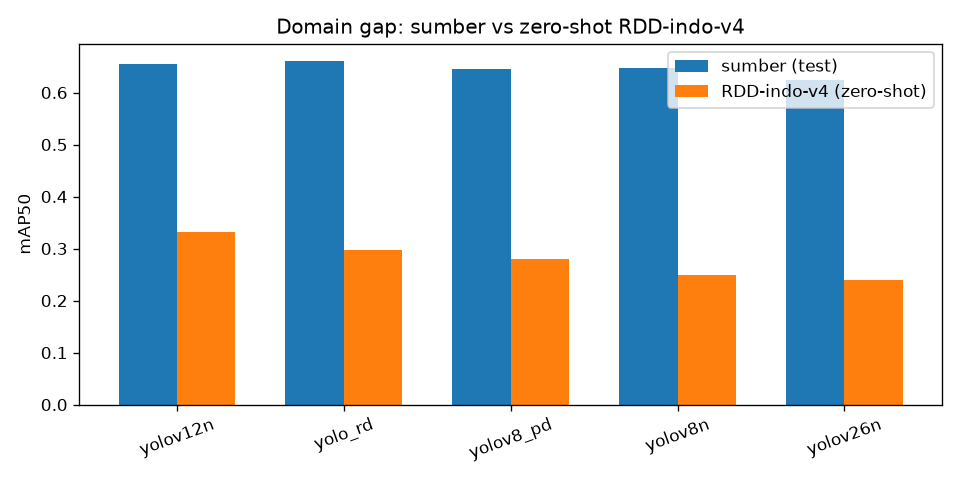

In [12]:
from IPython.display import Image, display
display(Image(str(EV / 'domain_gap.png')))  # fallback agnostik-backend

## ***Visualisasi Prediksi (Sampel Acak)***
---
Sampel acak (seed 42, bukan 6 citra pertama) model terbaik. Sel berikutnya membandingkan GT vs prediksi pada 4 citra acak lain (seed 7).

model visual: yolov12n mAP50=0.332


sampel acak: ['Merge-1_mp4-0451_jpg.rf.', 'Merge-1_mp4-0072_jpg.rf.', 'Merge-1_mp4-0766_jpg.rf.', 'Merge-1_mp4-0731_jpg.rf.', 'Merge-1_mp4-0716_jpg.rf.', 'Merge-1_mp4-0537_jpg.rf.']


<Figure size 1200x800 with 6 Axes>

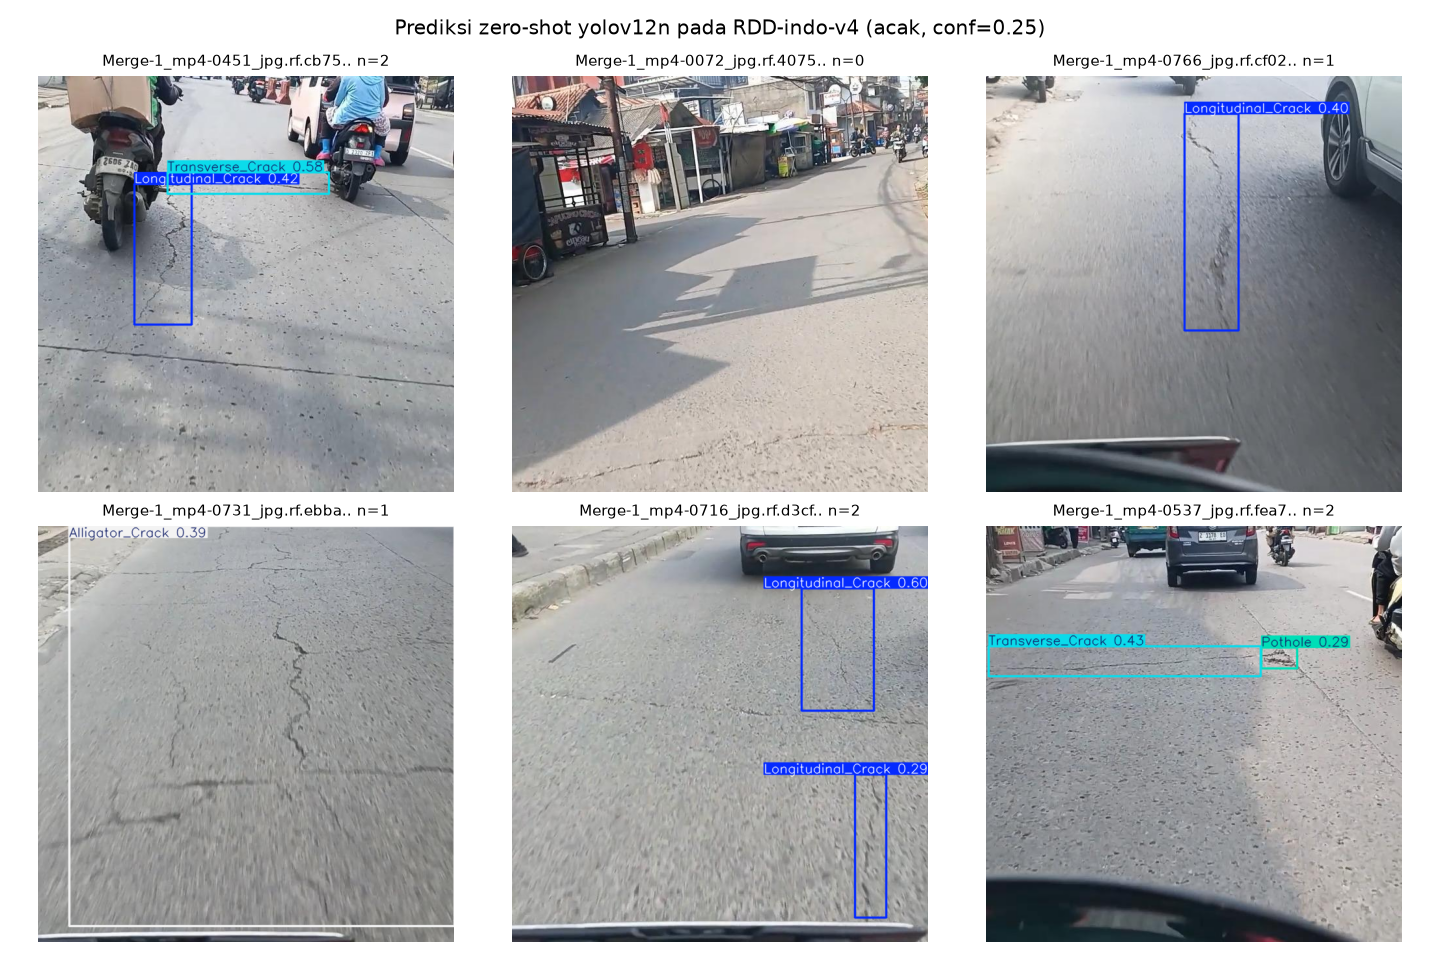

In [13]:
import random
from IPython.display import Image as IPImage, display

PRED_SEED = 42
best = max(ZS, key=lambda k: ZS[k]['mAP50'])
print('model visual:', best, f"mAP50={ZS[best]['mAP50']:.3f}")
bm = YOLO(str(WEIGHTS[best]))
all_imgs = sorted((REM / 'test/images').glob('*'))
imgs = random.Random(PRED_SEED).sample(all_imgs, 6)
print('sampel acak:', [p.name[:24] for p in imgs])
res = bm.predict([str(p) for p in imgs], imgsz=640, conf=0.25, iou=0.6, verbose=False, device=DEVICE)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(2, 3, figsize=(12, 8))
for a, r, p in zip(ax.flat, res, imgs):
    a.imshow(r.plot()[:, :, ::-1])
    a.set_title(f"{p.name[:28]}.. n={len(r.boxes)}", fontsize=9)
    a.axis('off')
plt.suptitle(f'Prediksi zero-shot {best} pada RDD-indo-v4 (acak, conf=0.25)')
plt.tight_layout()
plt.savefig(str(EV / 'zs_samples_pred_only.png'), dpi=120)
plt.show()
display(IPImage(str(EV / 'zs_samples_pred_only.png')))  # fallback agnostik-backend

### ***GT vs Prediksi (Sampel Acak)***
Kiri: ground-truth (label remap). Kanan: prediksi model terbaik. 4 citra acak seed 7.

sampel acak GT vs Pred: ['Merge-1_mp4-0837_jpg.rf.', 'Merge-1_mp4-0562_jpg.rf.', 'Merge-1_mp4-1119_jpg.rf.', 'Merge-1_mp4-0315_jpg.rf.']


<Figure size 1200x1600 with 8 Axes>

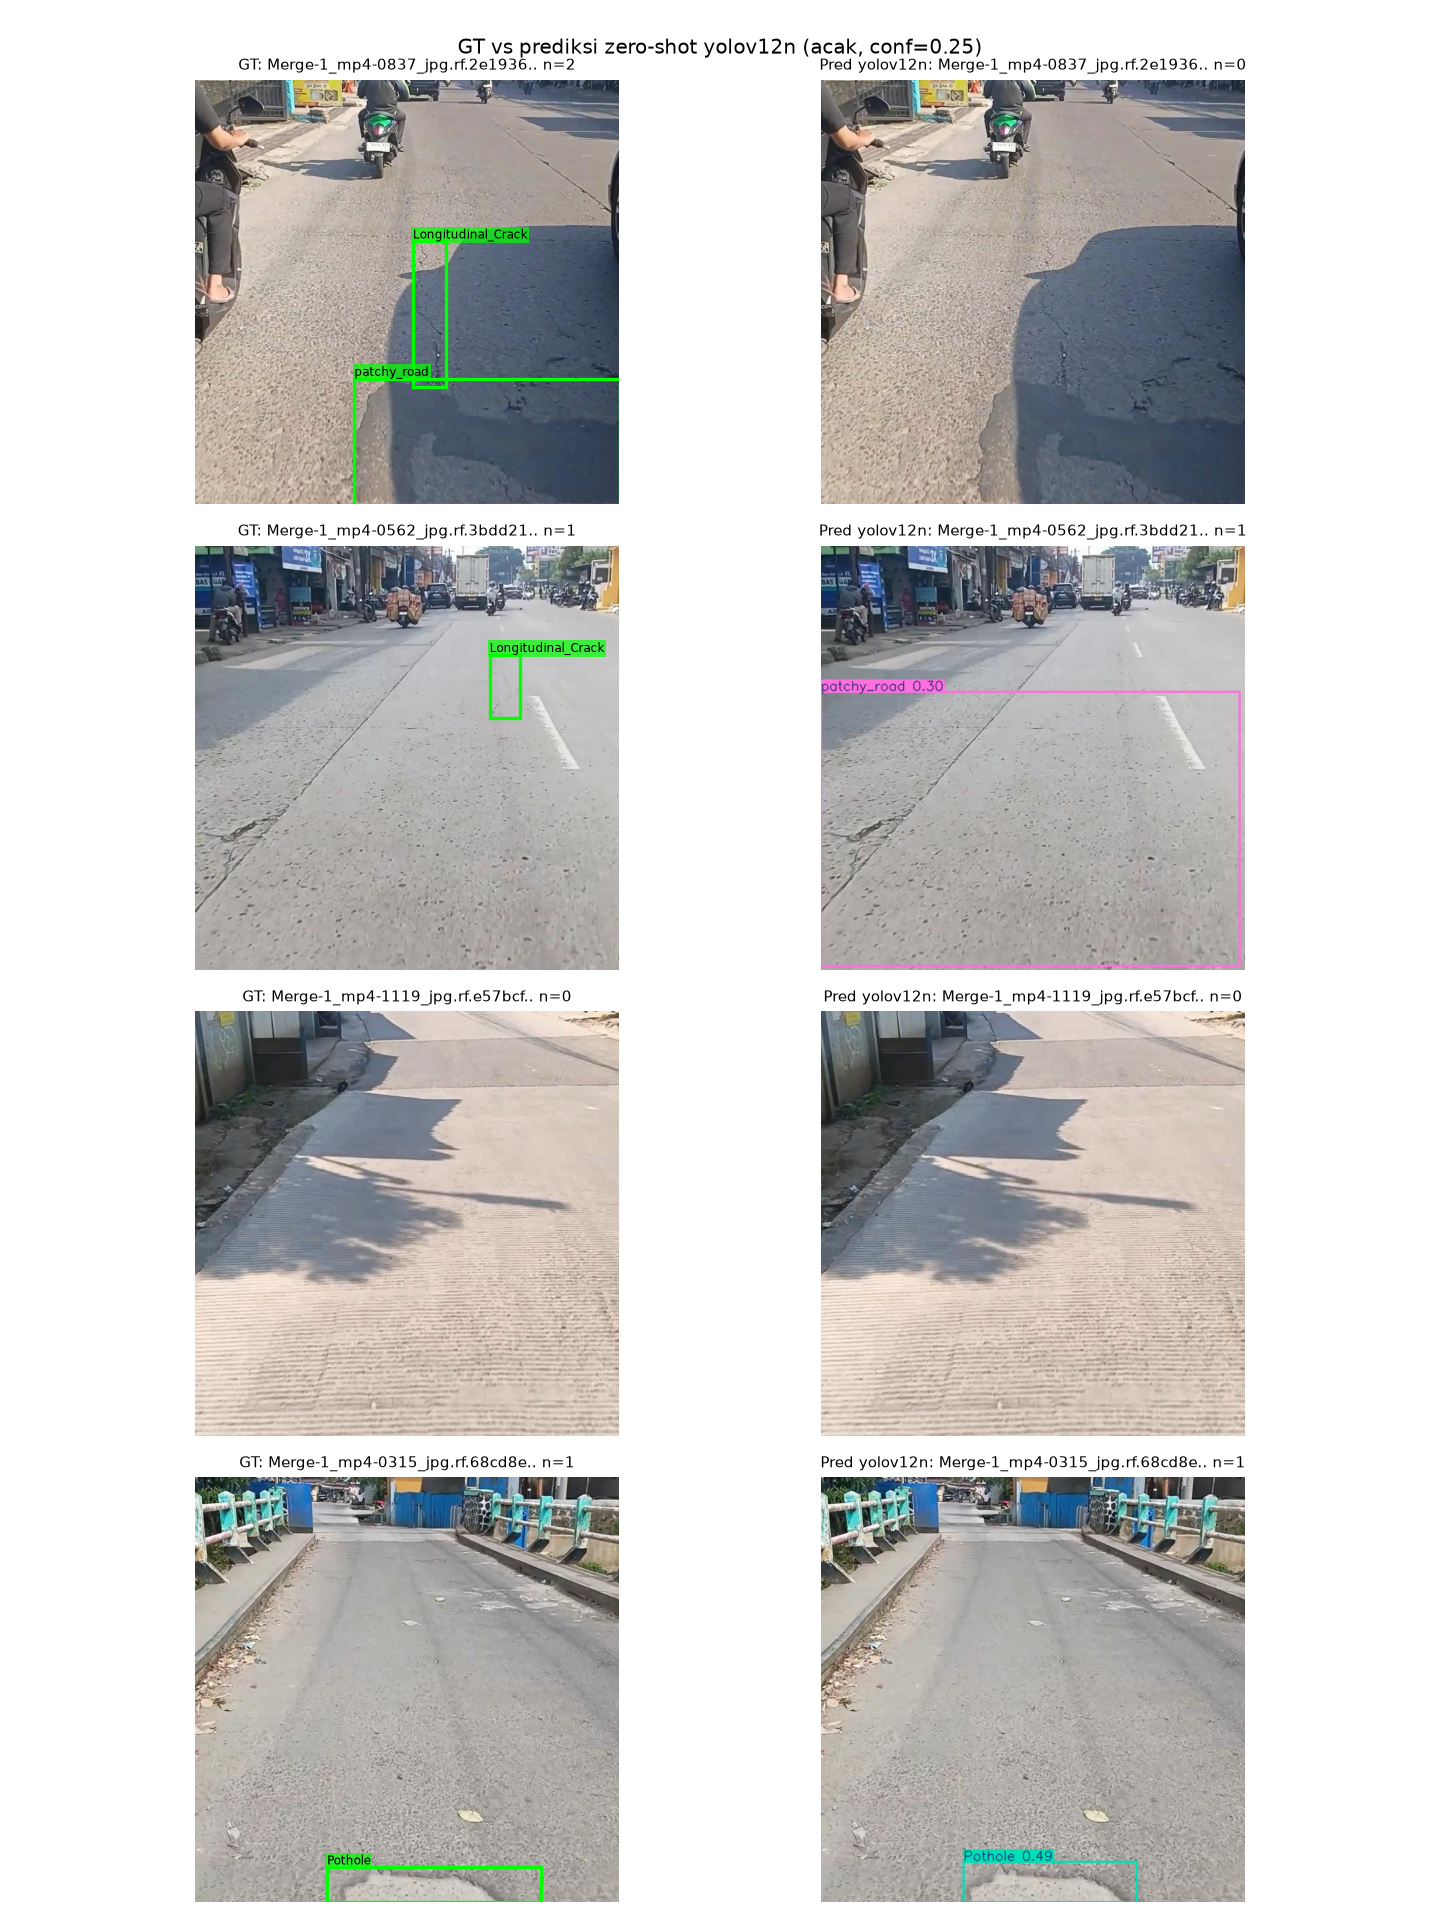

In [14]:
import random
from PIL import Image as PILImage
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import Image as IPImage, display
from ultralytics import YOLO

GT_SEED = 7
best_gt = max(ZS, key=lambda k: ZS[k]['mAP50'])
bmg = YOLO(str(WEIGHTS[best_gt]))
gt_imgs = random.Random(GT_SEED).sample(sorted((REM / 'test/images').glob('*')), 4)
print('sampel acak GT vs Pred:', [p.name[:24] for p in gt_imgs])
res_g = bmg.predict([str(p) for p in gt_imgs], imgsz=640, conf=0.25, iou=0.6, verbose=False, device=DEVICE)

GT_COLOR = 'lime'
fig, axes = plt.subplots(4, 2, figsize=(12, 16))
for row, (p, r) in enumerate(zip(gt_imgs, res_g)):
    im = PILImage.open(p).convert('RGB')
    W, H = im.size
    ax_gt, ax_pr = axes[row]
    ax_gt.imshow(im)
    n_gt = 0
    for l in (REM / 'test/labels' / (p.stem + '.txt')).read_text().splitlines():
        if not l.strip():
            continue
        q = l.split()
        cid, x, y, w, h = int(q[0]), *map(float, q[1:5])
        x0, y0 = (x - w / 2) * W, (y - h / 2) * H
        ax_gt.add_patch(patches.Rectangle((x0, y0), w * W, h * H, linewidth=2, edgecolor=GT_COLOR, facecolor='none'))
        ax_gt.text(x0, max(y0 - 4, 0), SRC_NAMES[cid], fontsize=7, color='black',
                   bbox=dict(facecolor=GT_COLOR, alpha=0.7, pad=1, edgecolor='none'))
        n_gt += 1
    ax_gt.set_title(f"GT: {p.name[:30]}.. n={n_gt}", fontsize=9)
    ax_gt.axis('off')
    ax_pr.imshow(r.plot()[:, :, ::-1])
    ax_pr.set_title(f"Pred {best_gt}: {p.name[:30]}.. n={len(r.boxes)}", fontsize=9)
    ax_pr.axis('off')
plt.suptitle(f'GT vs prediksi zero-shot {best_gt} (acak, conf=0.25)')
plt.tight_layout()
plt.savefig(str(EV / 'zs_samples_gt_vs_pred.png'), dpi=120)
plt.show()
display(IPImage(str(EV / 'zs_samples_gt_vs_pred.png')))  # fallback agnostik-backend

## ***Kesimpulan Sementara***
---
- Data target: RDD-indo-v4 hanya berisi split valid (307 citra, 307 file label, 39 kosong, 514 instans: longitudinal 235, tranverse 134, pothole 75, alligator 48, patchy road 22; tanpa kelas manhole). Mapping target-ke-sumber {0: 2, 1: 0, 2: 5, 3: 3, 4: 1} terverifikasi via nama kelas; isi valid/v4 dipakai sebagai split test remap.
- Hasil zero-shot (conf=0.001, iou=0.6; mAP50 dan macro F1 dirata-ratakan atas 5 kelas ber-GT): yolov12n terbaik (P=0.424, R=0.352, mAP50=0.332, mAP50-95=0.141, F1macro=0.378, F1weighted=0.464), disusul yolo_rd (P=0.401, R=0.298, mAP50=0.297, F1macro=0.332, F1weighted=0.431), yolov8_pd (P=0.343, R=0.308, mAP50=0.279, F1macro=0.305, F1weighted=0.402), yolov8n (P=0.304, R=0.311, mAP50=0.250, F1macro=0.306, F1weighted=0.392), yolov26n (P=0.280, R=0.295, mAP50=0.239, F1macro=0.274, F1weighted=0.359).
- Ranking: mAP50 dan F1 weighted persis 12n > RD > PD > 8n > 26n. F1 macro menukar 8n dan PD (0.306 vs 0.305, praktis seri) karena macro memberi bobot sama tiap kelas sehingga kelas kecil (patchy_road, support 22) lebih berpengaruh; sementara weighted F1 mengikuti volume instance dan urutannya identik dengan mAP50.
- Domain gap vs test sumber: 12n -0.322 (-49.2%), RD -0.364 (-55.0%), PD -0.367 (-56.8%), 8n -0.398 (-61.5%), 26n -0.386 (-61.7%).
- Per-kelas: kelas tersulit konsisten Pothole (F1 0.148-0.324) dan patchy_road (0.075-0.109); Longitudinal_Crack paling mudah (F1 0.513-0.603). Urutan peringkat antar model stabil di semua kelas ber-GT (12n teratas).
- Artefak: runs/rdd_yolov8n_local/evaluation/zero_shot_indo_v4/ (domain_gap.csv/png, zs_f1_summary.csv, zs_per_class_metrics.csv, zs_samples_pred_only.png, zs_samples_gt_vs_pred.png); label remap di runs/rdd_yolov8n_local/indo_v4_remapped/.
- Catatan implementasi: kelas `manhole` tidak punya GT di target sehingga tidak dievaluasi Ultralytics (bukan dihitung 0); `Metric.class_result(i)` bersifat posisional terhadap `ap_class_index`, bukan class-id.
